<a href="https://colab.research.google.com/github/isalinamartinez/beginning-bioinformatics/blob/main/Mod_11_IM_Classifying_Cells_from_Gene_Expression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q "pandas==2.2.3" "scanpy[leiden]" "pynndescent==0.6.0"

# <font color="purple">Module 11: Classifying Cells from Gene Expression</font>






## <font color="purple">Part 1: Scanpy Basics - Preprocessing and Clustering</font>


In [2]:
import scanpy as sc
import anndata as ad
import numpy as np
import pandas as pd

## <font color="purple">Scanpy Setup</font>


In [4]:
import pooch
sc.set_figure_params(dpi=50, facecolor="white")

## <font color="purple">Loading the Dataset</font>


In [5]:
EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("scverse_tutorials"),
    base_url="doi:10.6084/m9.figshare.22716739.v1/",
)
EXAMPLE_DATA.load_registry_from_doi()

In [11]:
list(EXAMPLE_DATA.registry.keys())

['s1d1_filtered_feature_bc_matrix.h5', 's1d3_filtered_feature_bc_matrix.h5']

In [10]:
adata1 = sc.read_10x_h5(
    EXAMPLE_DATA.fetch("s1d1_filtered_feature_bc_matrix.h5")
)

adata1

/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 8785 × 36601
    var: 'gene_ids', 'feature_types', 'genome', 'pattern', 'read', 'sequence'

### <font color="purple">Making Gene Names Unique</font>

In [12]:
adata1.var_names_make_unique()

In [13]:
adata2 = sc.read_10x_h5(
    EXAMPLE_DATA.fetch("s1d3_filtered_feature_bc_matrix.h5")
)
adata2.var_names_make_unique()
adata2

/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 8340 × 36601
    var: 'gene_ids', 'feature_types', 'genome', 'pattern', 'read', 'sequence'

## <font color="purple">Combining the Samples</font>


In [14]:
adata = ad.concat(
    {"s1d1": adata1, "s1d3": adata2},
    label="sample",
    index_unique="-"
)
adata

AnnData object with n_obs × n_vars = 17125 × 36601
    obs: 'sample'


## <font color="purple">Preserving Raw Gene Counts</font>


In [15]:
adata.layers["counts"] = adata.X.copy()

## <font color="purple">Quality Control</font>

In [16]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)

In [17]:
adata.obs[
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"]
].head()

,n_genes_by_counts,total_counts,pct_counts_mt
AAACCCAAGGATGGCT-1-s1d1,2103,8663.0,5.309938
AAACCCAAGGCCTAGA-1-s1d1,3916,12853.0,13.926710
AAACCCAAGTGAGTGC-1-s1d1,683,1631.0,35.622318
AAACCCACAAGAGGCT-1-s1d1,4330,17345.0,4.496973
AAACCCACATCGTGGC-1-s1d1,325,555.0,28.648647



## <font color="purple">Visualizing Quality Control Metrics</font>


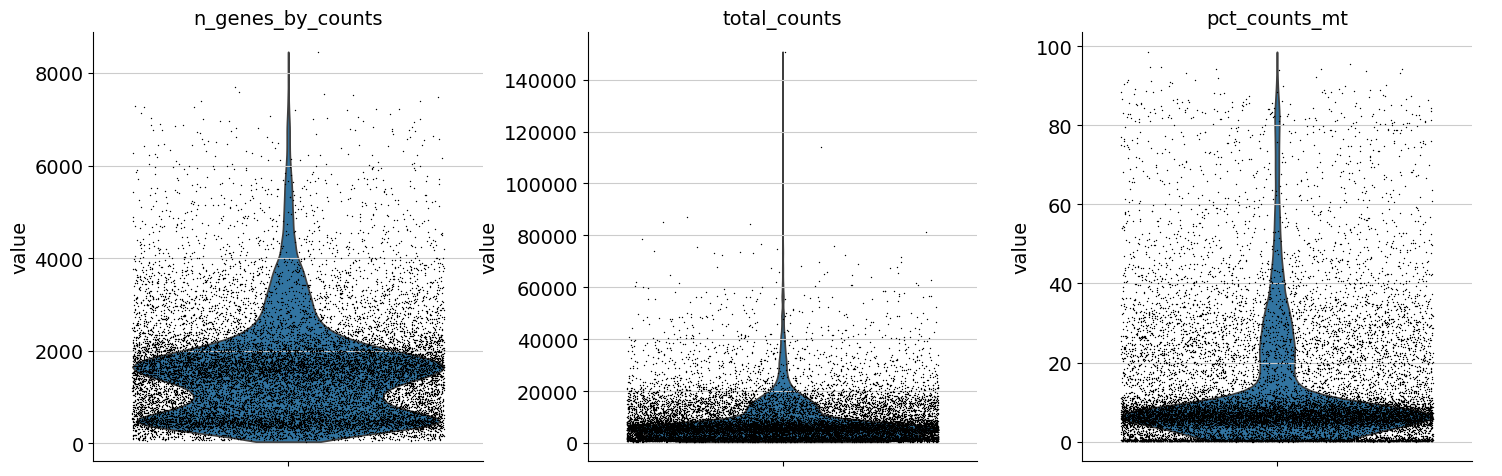

In [18]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True
)

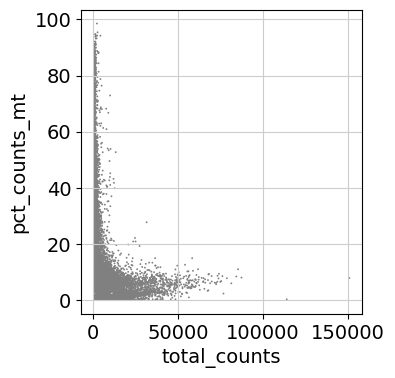

In [19]:
sc.pl.scatter(
    adata,
    x="total_counts",
    y="pct_counts_mt"
)

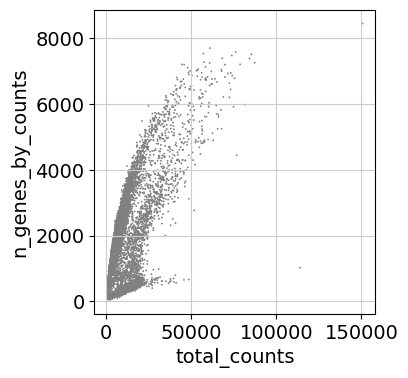

In [20]:
sc.pl.scatter(
    adata,
    x="total_counts",
    y="n_genes_by_counts"
)

In [21]:
qc_pass = (
    (adata.obs["n_genes_by_counts"] >= 200)
    & (adata.obs["n_genes_by_counts"] <= 5000)
    & (adata.obs["pct_counts_mt"] < 20)
)

print("Total cells:", adata.n_obs)
print("Cells passing QC:", qc_pass.sum())
print("Cells flagged:", (~qc_pass).sum())

Total cells: 17125
Cells passing QC: 13301
Cells flagged: 3824



## <font color="purple">Filtering Cells and Genes</font>


In [22]:
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=3)
adata

AnnData object with n_obs × n_vars = 17041 × 23427
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    layers: 'counts'

In [23]:
print("Filtered data:", adata.shape)
print("Saved counts:", adata.layers["counts"].shape)

Filtered data: (17041, 23427)
Saved counts: (17041, 23427)



## <font color="purple">Normalization</font>


In [24]:
sc.pp.normalize_total(adata, target_sum=1e4)


## <font color="purple">Log Transformation</font>


In [25]:
sc.pp.log1p(adata)

## <font color="purple">Highly Variable Genes</font>

In [26]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000
)

In [27]:
print("Total genes:", adata.n_vars)
print("Highly variable genes:", adata.var["highly_variable"].sum())

Total genes: 23427
Highly variable genes: 2000



## <font color="purple">Principal Component Analysis (PCA)</font>


In [28]:
sc.pp.pca(
    adata,
    mask_var="highly_variable"
)

In [29]:
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40)


## <font color="purple">UMAP Visualization</font>


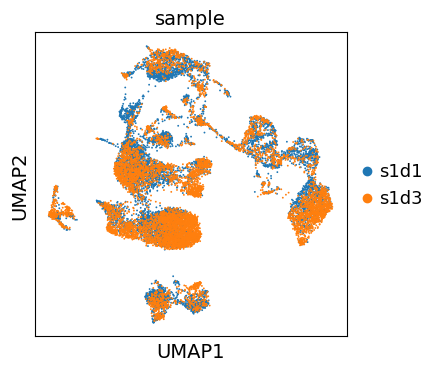

In [30]:
sc.tl.umap(adata)
sc.pl.umap(adata, color="sample")

## <font color="purple">Leiden Clustering</font>

/tmp/ipykernel_2101/2730140518.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=0.5, key_added="leiden")


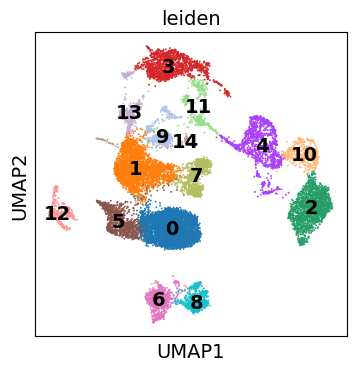

In [31]:
sc.tl.leiden(adata, resolution=0.5, key_added="leiden")
sc.pl.umap(adata, color="leiden", legend_loc="on data")


## <font color="purple">Differentially Expressed Genes as Markers</font>


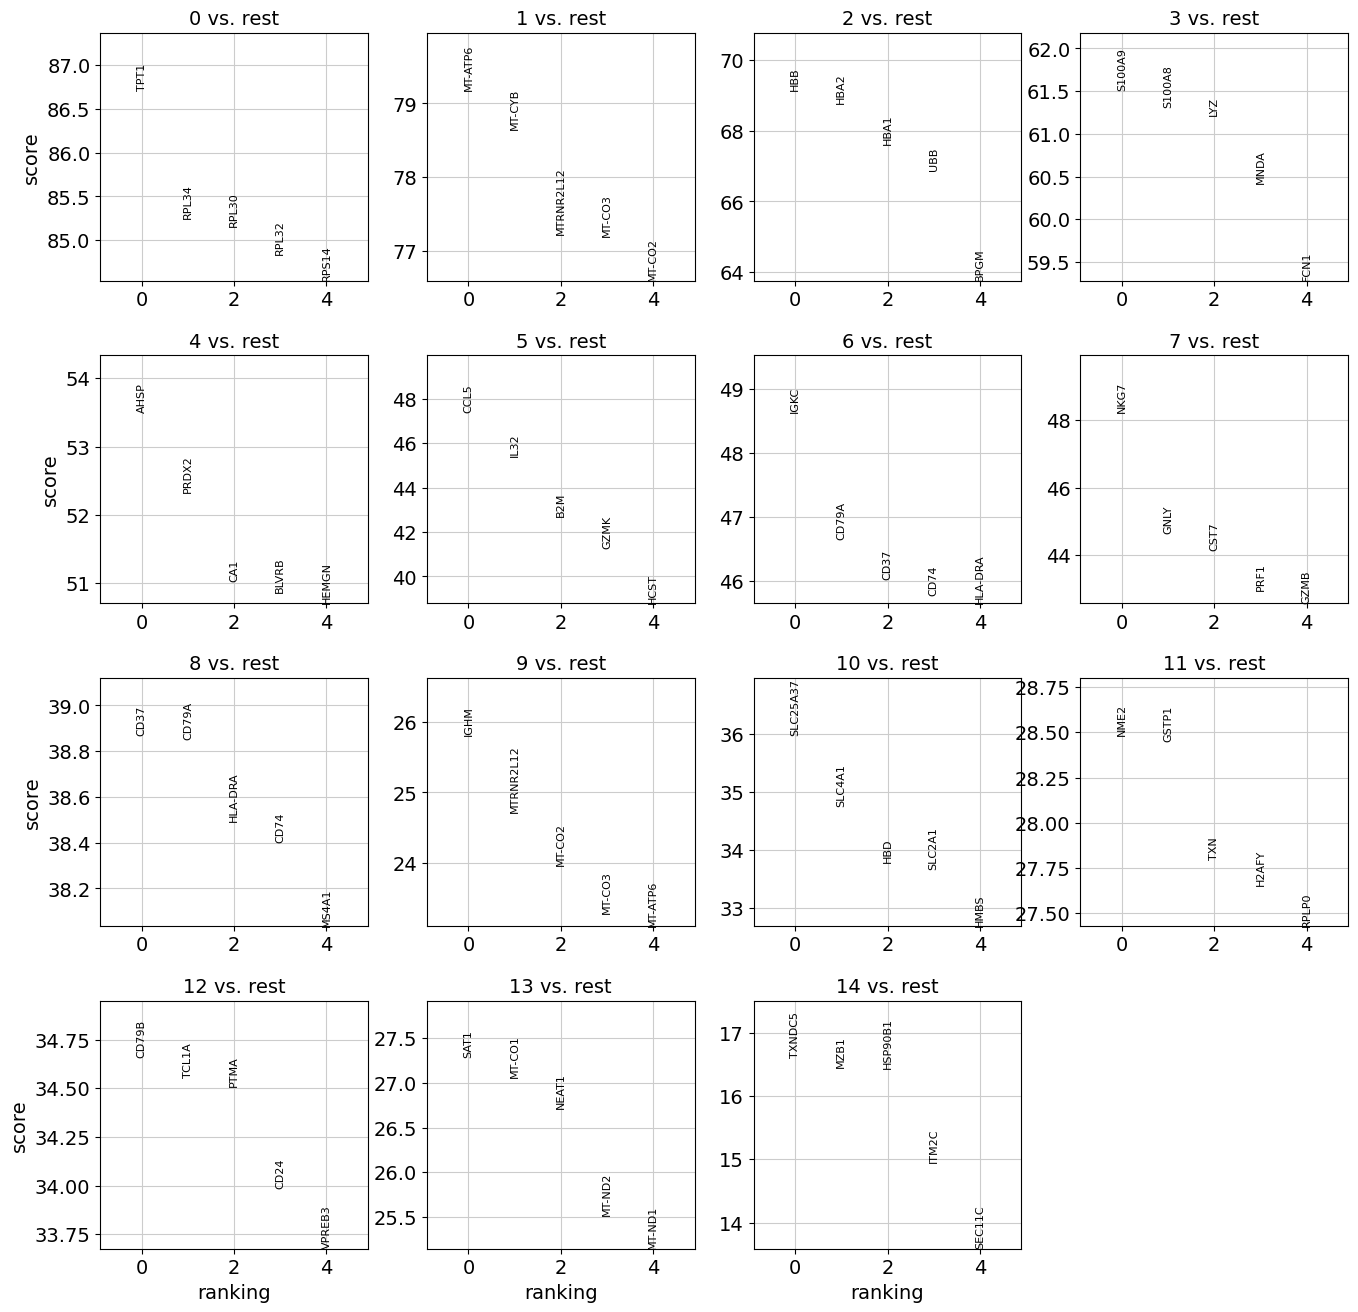

In [32]:
sc.tl.rank_genes_groups(
    adata,
    groupby="leiden",
    method="wilcoxon"
)
sc.pl.rank_genes_groups(
    adata,
    n_genes=5,
    sharey=False
)

In [33]:
print(adata.obs.columns.tolist())

['sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'leiden']


In [34]:
sc.get.rank_genes_groups_df(
    adata,
    group="0"
)[["names", "scores", "pvals_adj"]].head(10)

,names,scores,pvals_adj
0,TPT1,86.717300,0.0
1,RPL34,85.252983,0.0
2,RPL30,85.155762,0.0
3,RPL32,84.837807,0.0
4,RPS14,84.535164,0.0
5,RPS15A,84.437508,0.0
6,RPS12,84.431122,0.0
7,RPS29,83.681946,0.0
8,RPL13,83.468094,0.0
9,RPL9,82.813675,0.0


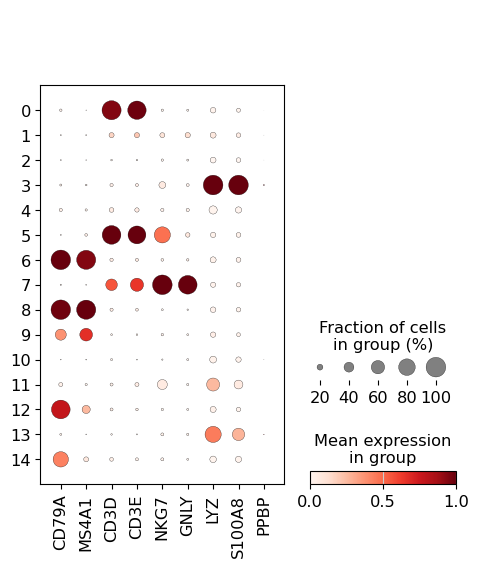

In [35]:
sc.pl.dotplot(
    adata,
    var_names=[
        "CD79A", "MS4A1",
        "CD3D", "CD3E",
        "NKG7", "GNLY",
        "LYZ", "S100A8",
        "PPBP"
    ],
    groupby="leiden",
    standard_scale="var"
)

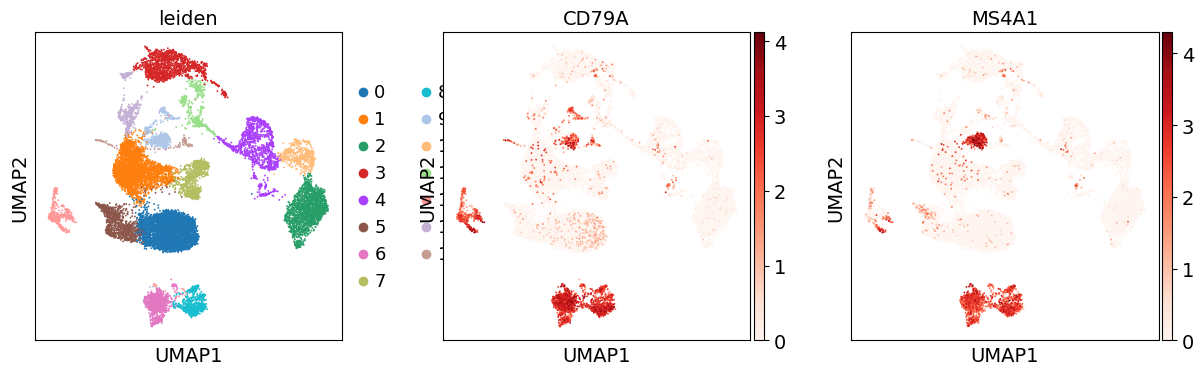

In [36]:
sc.pl.umap(
    adata,
    color=["leiden", "CD79A", "MS4A1"],
    cmap="Reds"
)

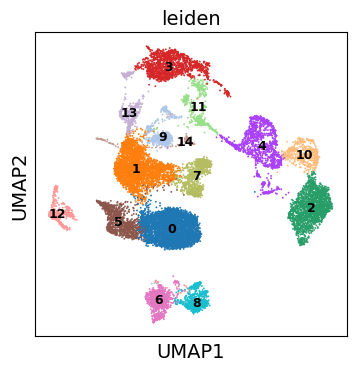

In [37]:
sc.pl.umap(
    adata,
    color="leiden",
    legend_loc="on data",
    legend_fontsize=9
)

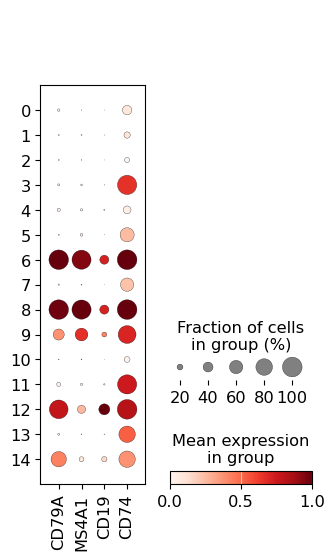

In [38]:
sc.pl.dotplot(
    adata,
    var_names=["CD79A", "MS4A1", "CD19", "CD74"],
    groupby="leiden",
    standard_scale="var"
)


## <font color="purple">Preliminary Cell-Type Annotation</font>


In [39]:
b_cell_clusters = ["6", "8", "9"]

adata.obs["cell_type_lvl1"] = np.where(
    adata.obs["leiden"].isin(b_cell_clusters),
    "B Cells",
    "Other"
)
print(adata.obs["cell_type_lvl1"].value_counts())

cell_type_lvl1
Other      14979
B Cells     2062
Name: count, dtype: int64



<h1><font color="purple">Part 2: Classifying Cells from Gene Expression</font></h1>


<h2><font color="purple">Cell 1: Import Tools and Define Settings</font></h2>

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse
from IPython.display import display

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay,
    classification_report,
)

SEED = 42
LABEL_COLUMN = "cell_type_lvl1"
POSITIVE_LABEL = "B Cells"
N_GENES = 500
N_JOBS = 2


## <font color="purple">Cell 2: Prepare Data and Split into Training, Validation, and Test Sets</font>


In [41]:
if LABEL_COLUMN not in adata.obs:
    raise ValueError("Run the tutorial's cell-type annotation cell first.")

if "counts" not in adata.layers:
    raise ValueError("The tutorial's saved counts layer is missing.")

# Exclude cells with missing annotations.
keep = adata.obs[LABEL_COLUMN].notna().to_numpy()
labels = adata.obs.loc[keep, LABEL_COLUMN].astype(str)

if POSITIVE_LABEL not in labels.unique():
    raise ValueError(
        f"{POSITIVE_LABEL!r} was not found. "
        f"Available labels: {sorted(labels.unique())}"
    )

y = (labels == POSITIVE_LABEL).to_numpy(dtype=int)
cell_indices = np.flatnonzero(keep)

# Copy the saved counts into a separate sparse matrix.
X = sparse.csr_matrix(
    adata.layers["counts"][keep], dtype=np.float64
).copy()

if not np.isfinite(X.data).all() or (X.data < 0).any():
    raise ValueError("Expected finite, nonnegative counts.")

if np.any(np.asarray(X.sum(axis=1)).ravel() == 0):
    raise ValueError("Found cells with zero total counts.")

# Each cell is transformed independently using a fixed target.
X = normalize(X, norm="l1", axis=1) * 10_000
X.data = np.log1p(X.data)
X = X.tocsr()

# Reserve 20% for testing.
indices = np.arange(len(y))
trainval_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)

# Reserve 25% of the remaining 80% for validation.
train_idx, val_idx = train_test_split(
    trainval_idx,
    test_size=0.25,
    stratify=y[trainval_idx],
    random_state=SEED,
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

if np.bincount(y_train, minlength=2).min() < 5:
    raise ValueError(
        "Five-fold CV requires at least five training cells per class."
    )

summary = pd.DataFrame([
    {
        "Partition": name,
        "Cells": len(target),
        "B Cells": int(target.sum()),
        "Other cells": int((target == 0).sum()),
        "B-cell fraction": target.mean(),
    }
    for name, target in [
        ("Training", y_train),
        ("Validation", y_val),
        ("Test", y_test),
    ]
])

display(summary.round(3))
print("Positive class: B Cells (1)")
print("Negative class: other annotated cells (0)")
print("Expression matrix:", X.shape)

,Partition,Cells,B Cells,Other cells,B-cell fraction
0,Training,10224,1238,8986,0.121
1,Validation,3408,412,2996,0.121
2,Test,3409,412,2997,0.121


Positive class: B Cells (1)
Negative class: other annotated cells (0)
Expression matrix: (17041, 23427)


## <font color="purple">Cell 3: Define Classifiers and Hyperparameter Grids</font>


In [42]:
def make_classifier_pipeline(classifier, scale=False):
    steps = [
        ("remove_constant", VarianceThreshold()),
        ("select_genes", SelectKBest(score_func=f_classif, k=N_GENES)),
    ]

    if scale:
        steps.append(("scale", StandardScaler(with_mean=False)))

    steps.append(("classifier", classifier))
    return Pipeline(steps)


model_specs = {
    "Logistic regression": (
        make_classifier_pipeline(
            LogisticRegression(
                solver="liblinear",
                max_iter=5000,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.01, 0.1, 1.0],
        },
    ),

    "Random forest": (
        make_classifier_pipeline(
            RandomForestClassifier(
                n_estimators=200,
                random_state=SEED,
                n_jobs=1,
            )
        ),
        {
            "classifier__max_depth": [10, None],
            "classifier__min_samples_leaf": [1, 5],
        },
    ),

    "RBF SVM": (
        make_classifier_pipeline(
            SVC(
                kernel="rbf",
                probability=False,
                cache_size=300,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.1, 1.0],
            "classifier__gamma": ["scale", 0.001],
        },
    ),
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)


## <font color="purple">Cell 4: Grid Search and Model Selection</font>

In [43]:
def positive_scores(model, features):
    """Return continuous scores for positive class 1."""
    if hasattr(model, "predict_proba"):
        positive_column = np.flatnonzero(model.classes_ == 1)[0]
        return model.predict_proba(features)[:, positive_column]

    if not np.array_equal(model.classes_, np.array([0, 1])):
        raise ValueError("Expected binary classes [0, 1].")

    return model.decision_function(features)


searches = {}
validation_scores = {}
comparison_rows = []

for name, (pipeline, grid) in model_specs.items():
    print(f"\nRunning five-fold grid search: {name}")

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=grid,
        scoring="average_precision",
        cv=cv,
        refit=True,
        n_jobs=N_JOBS,
        pre_dispatch=N_JOBS,
        return_train_score=False,
        error_score="raise",
        verbose=1,
    )

    # Only training data enter grid search.
    search.fit(X_train, y_train)
    searches[name] = search

    scores = positive_scores(search.best_estimator_, X_val)
    validation_scores[name] = scores

    comparison_rows.append({
        "Classifier": name,
        "CV average precision": search.best_score_,
        "CV AP SD": search.cv_results_["std_test_score"][search.best_index_],
        "Validation average precision": average_precision_score(y_val, scores),
        "Validation ROC-AUC": roc_auc_score(y_val, scores),
        "Best parameters": search.best_params_,
    })

comparison = (
    pd.DataFrame(comparison_rows)
    .set_index("Classifier")
    .sort_values(
        "Validation average precision",
        ascending=False,
        kind="stable",
    )
)

display(comparison.round(4))

winner_name = comparison.index[0]
winner_model = searches[winner_name].best_estimator_

print(f"\nSelected classifier: {winner_name}")
print("Selection criterion: highest validation average precision")
print("The test set has not been used for model selection.")


Running five-fold grid search: Logistic regression
Fitting 5 folds for each of 3 candidates, totalling 15 fits

Running five-fold grid search: Random forest
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Running five-fold grid search: RBF SVM
Fitting 5 folds for each of 4 candidates, totalling 20 fits


,CV average precision,CV AP SD,Validation average precision,Validation ROC-AUC,Best parameters
Classifier,,,,,
RBF SVM,0.9957,0.0013,0.9953,0.9994,"{'classifier__C': 1.0, 'classifier__gamma': 0...."
Random forest,0.9958,0.0017,0.9938,0.9992,"{'classifier__max_depth': None, 'classifier__m..."
Logistic regression,0.9921,0.0014,0.9902,0.9986,{'classifier__C': 0.01}



Selected classifier: RBF SVM
Selection criterion: highest validation average precision
The test set has not been used for model selection.



## <font color="purple">Cell 5: Validation ROC Curves</font>

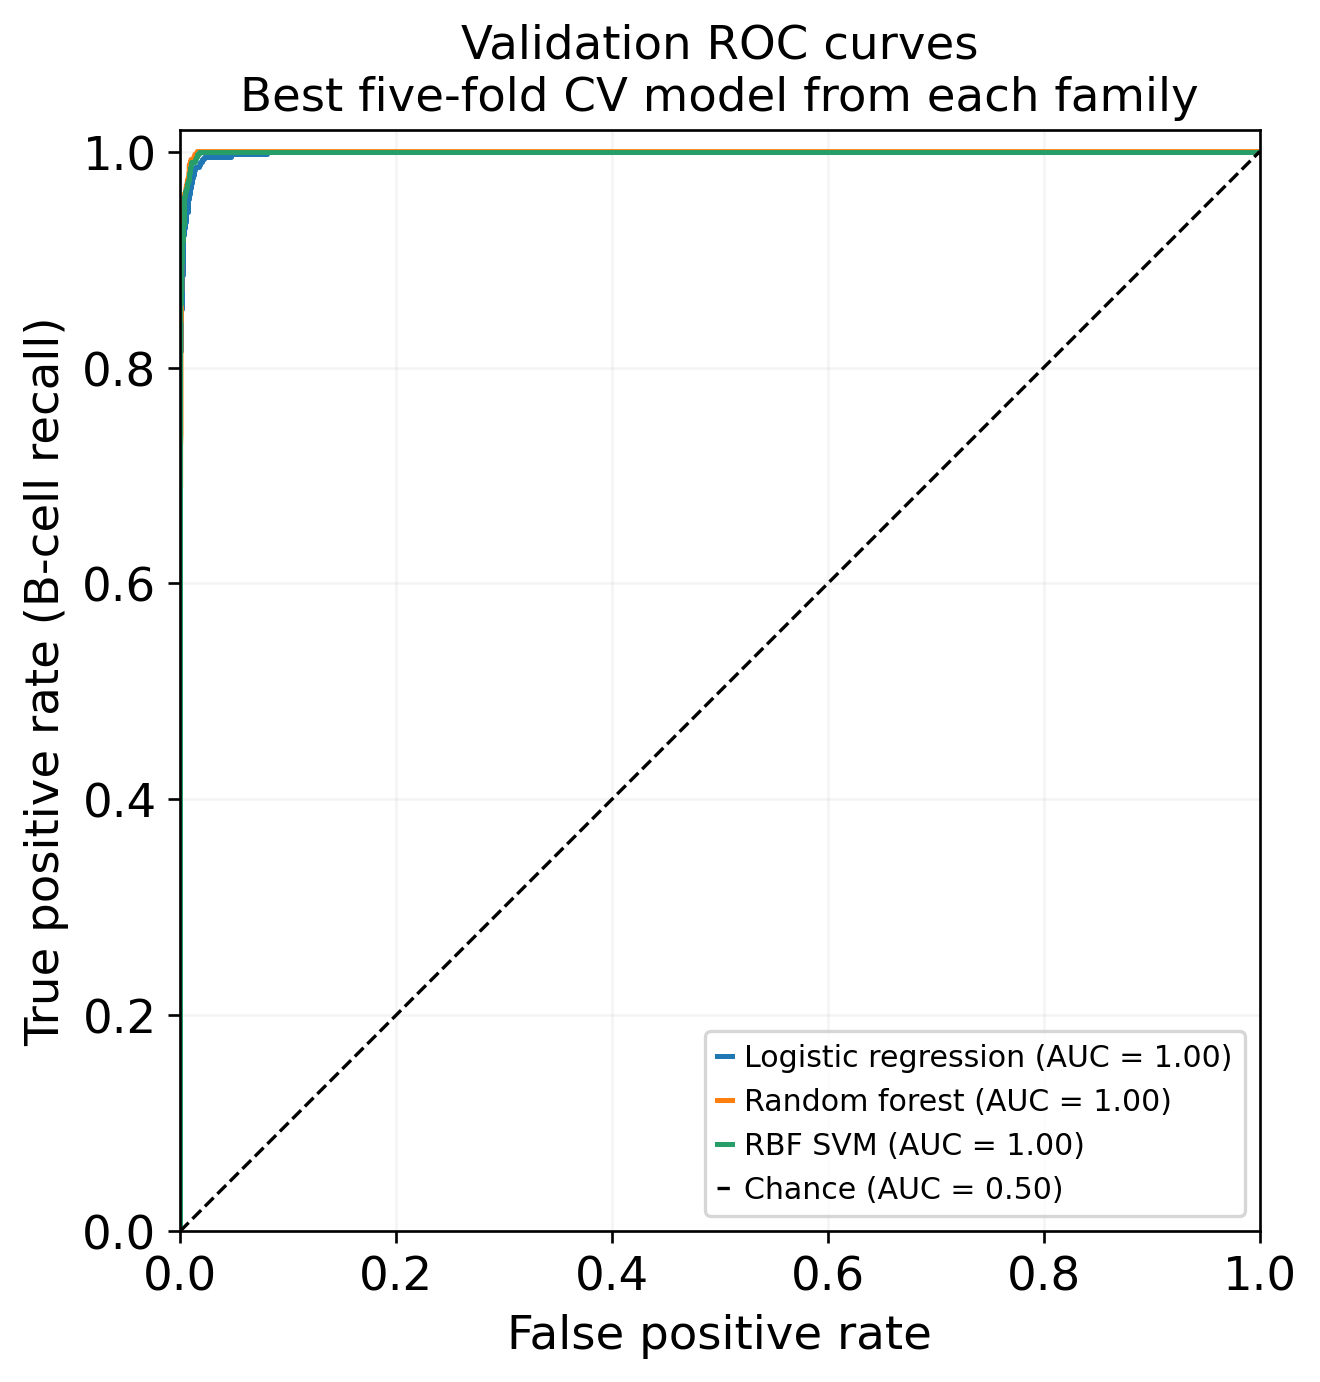

Winner by validation average precision: RBF SVM
ROC-AUC is displayed for comparison; it did not choose the winner.


In [45]:
fig, ax = plt.subplots(figsize=(7, 6), dpi=120)

for name, scores in validation_scores.items():
    RocCurveDisplay.from_predictions(
        y_val,
        scores,
        name=name,
        ax=ax,
    )

ax.plot(
    [0, 1], [0, 1],
    "k--",
    linewidth=1,
    label="Chance (AUC = 0.50)",
)
ax.set(
    title="Validation ROC curves\nBest five-fold CV model from each family",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    f"Winner by validation average precision: {winner_name}\n"
    "ROC-AUC is displayed for comparison; it did not choose the winner."
)


## <font color="purple">Cell 6: Final Test Evaluation</font>

Final test evaluation: RBF SVM
Test average precision: 0.9939
Test ROC-AUC:           0.9989
Test B-cell prevalence: 0.1209

Classification report at the model's default threshold:

                       precision    recall  f1-score   support

Other annotated cells      0.995     0.995     0.995      2997
              B Cells      0.961     0.964     0.962       412

             accuracy                          0.991      3409
            macro avg      0.978     0.979     0.979      3409
         weighted avg      0.991     0.991     0.991      3409



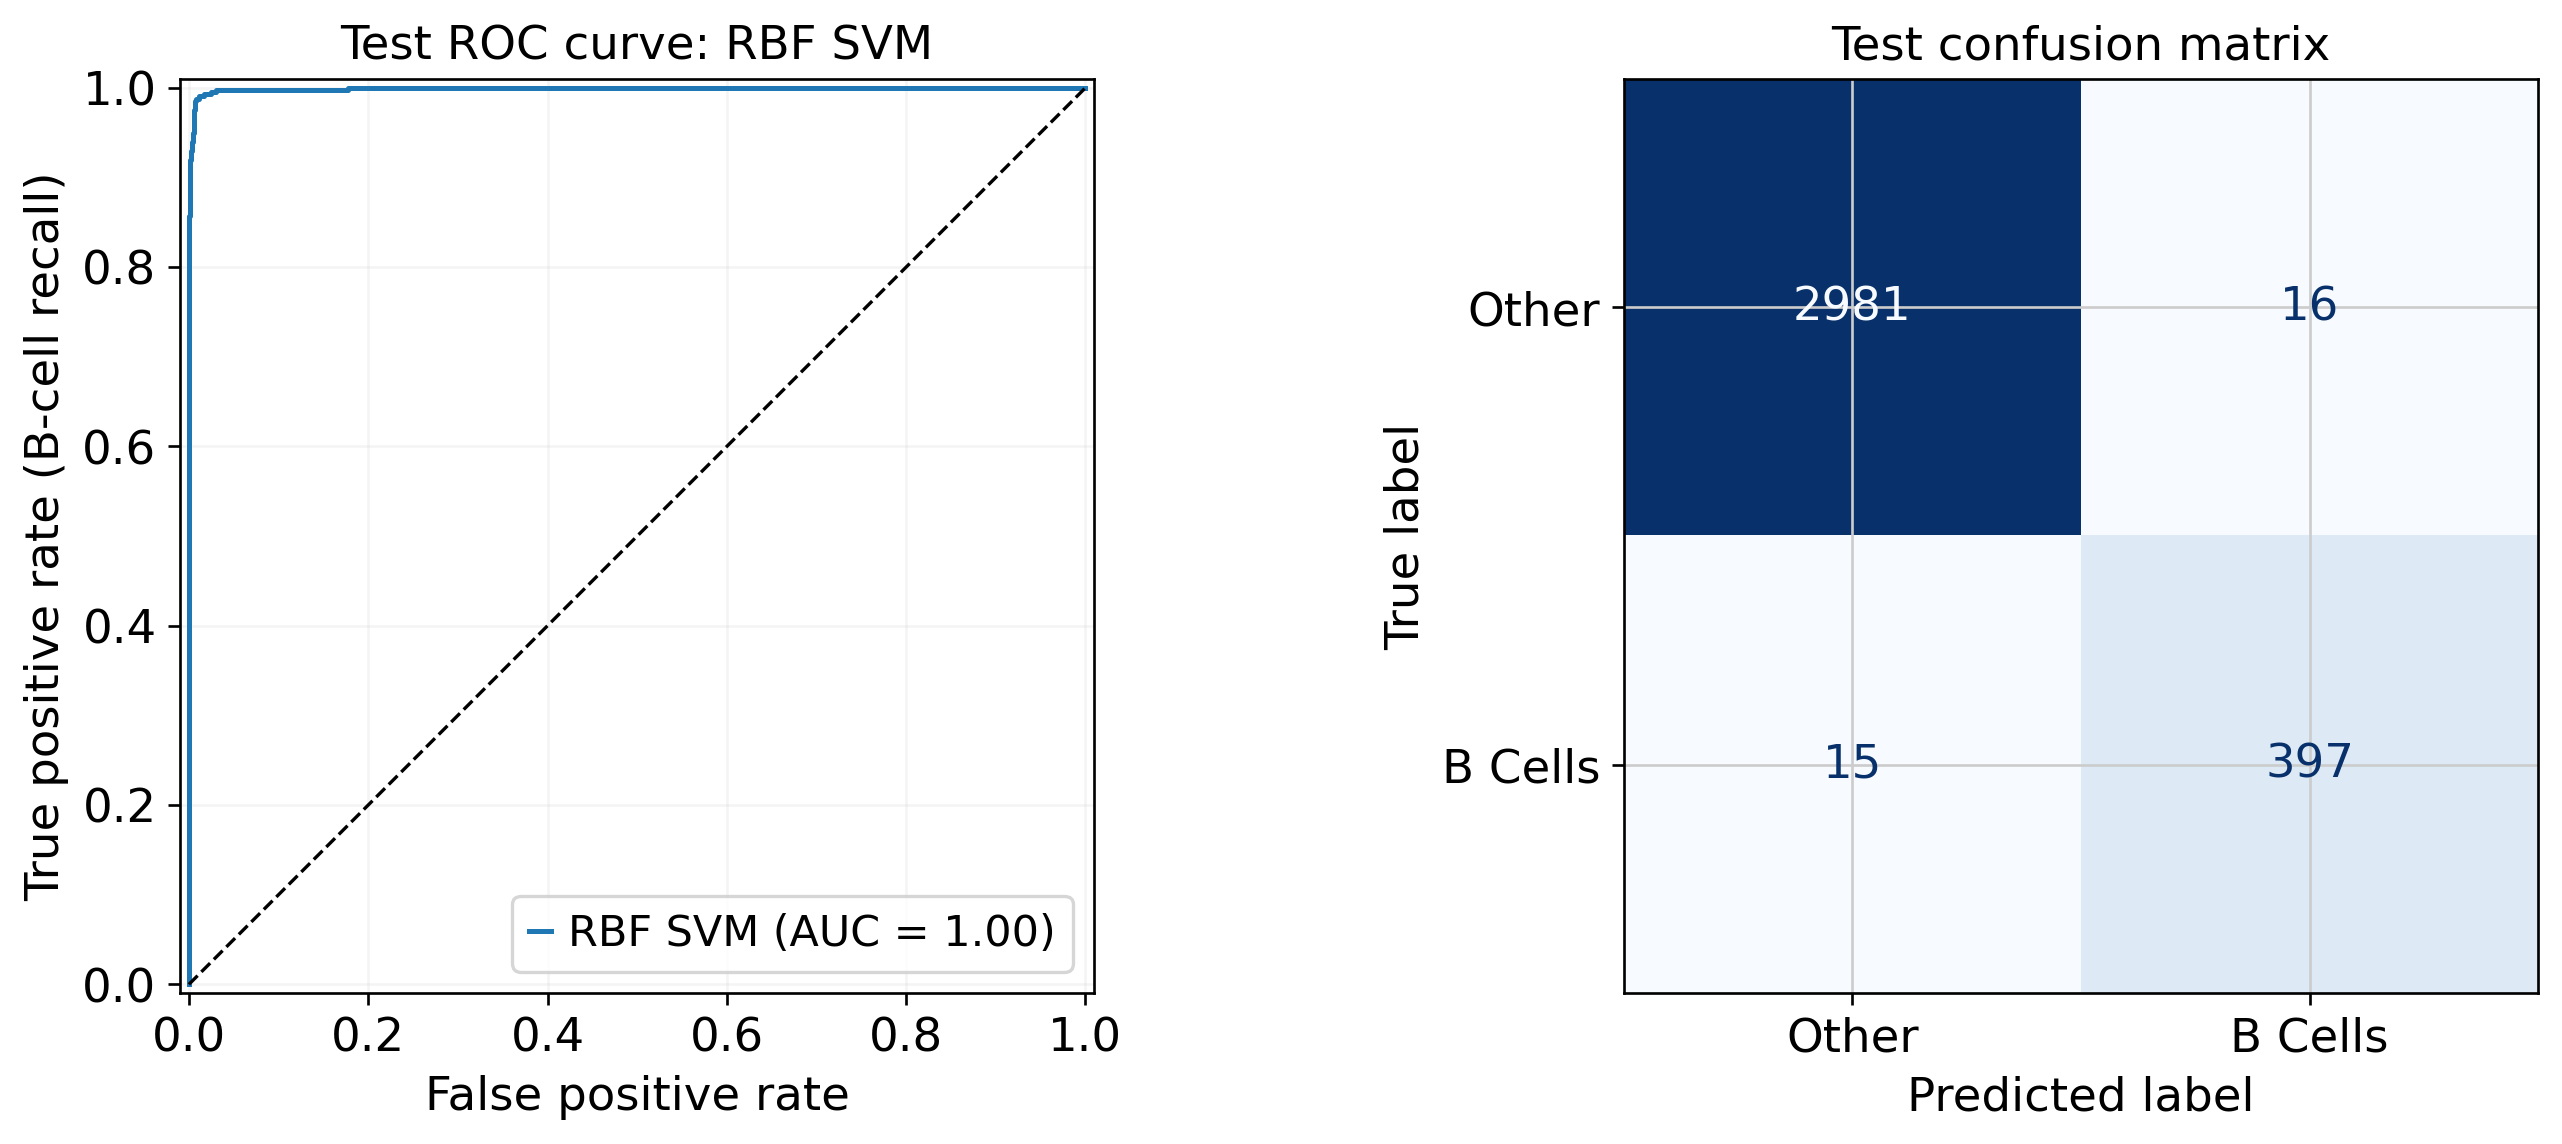

,cell_id,reference_label,predicted_label,positive_class_score,correct
0,TATCGCCTCATCTCTA-1-s1d1,0,0,-2.544449,True
1,CTCATTACAGGCCCTA-1-s1d1,0,0,-1.330065,True
2,CGATGCGAGGTGTGAC-1-s1d1,0,0,-2.916318,True
3,AACGAAACACATTGTG-1-s1d1,1,1,1.019780,True
4,GACCAATAGCCAACCC-1-s1d1,0,0,-2.886344,True


In [46]:
test_scores = positive_scores(winner_model, X_test)
test_predictions = winner_model.predict(X_test)

test_ap = average_precision_score(y_test, test_scores)
test_auc = roc_auc_score(y_test, test_scores)

print(f"Final test evaluation: {winner_name}")
print(f"Test average precision: {test_ap:.4f}")
print(f"Test ROC-AUC:           {test_auc:.4f}")
print(f"Test B-cell prevalence: {y_test.mean():.4f}")
print("\nClassification report at the model's default threshold:\n")

print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Other annotated cells", "B Cells"],
    digits=3,
    zero_division=0,
))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)

RocCurveDisplay.from_predictions(
    y_test,
    test_scores,
    name=winner_name,
    ax=axes[0],
)
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set(
    title=f"Test ROC curve: {winner_name}",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
)
axes[0].grid(alpha=0.2)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Other", "B Cells"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=axes[1],
)
axes[1].set_title("Test confusion matrix")

plt.tight_layout()
plt.show()

test_results = pd.DataFrame({
    "cell_id": adata.obs_names[cell_indices[test_idx]].to_numpy(),
    "reference_label": y_test,
    "predicted_label": test_predictions,
    "positive_class_score": test_scores,
})
test_results["correct"] = (
    test_results["reference_label"] == test_results["predicted_label"]
)

display(test_results.head())


## Cell 7: Exit Questions

### 1. Define the classification problem

What are the observations, predictor features, and target labels in this classification problem?

<font color="purple">The observations are the individual cells. We use their gene expression levels to predict whether they fall into the B Cells or Other categories.</font>

### 2. Establish a baseline

Using the training partition, calculate the accuracy of a classifier that predicts "Other" for every cell. What would its B-cell recall be? Why stratify the split?

<font color="purple">The baseline accuracy is 8,986 / 10,224 = 87.9%. The B-cell recall is 0% because the classifier only predicts Other, so it doesn't recognize any B Cells. We stratify the data so each group has about the same proportion of B Cells and Other cells. That way, we have B Cells in each group to test the classifier.</font>

### 3. Identify the selected model

Which classifier was selected, and what were its best hyperparameters?

<font color="purple">RBF SVM was selected because it had the highest validation average precision of 0.9953. Its best hyperparameters were C = 1.0 and gamma = 0.001.</font>

### 4. Interpret what the classifier learned

What did the classifier learn to predict? How does this differ from independently establishing a cell's biological identity?

<font color="purple">The classifier learned to recognize gene expression patterns to predict whether a cell falls into the B Cells or Other category. This doesn't necessarily mean it confirmed the cell's biological identity because it was learning from the labels we already assigned.</font>

### 5. Interpret classification errors

What would a false positive and a false negative mean in this analysis?

<font color="purple">A false positive would be when the classifier predicts B Cell, but the cell is actually labeled Other. A false negative would be when the classifier predicts Other, but the cell is actually labeled B Cell.</font>

### 6. Evaluate the classifier

Is the selected classifier a good classifier for this task? Justify your answer using its test-set sensitivity, precision, specificity, and F1 score. Calculate specificity from the confusion matrix as TN / (TN + FP).

<font color="purple">Yes, I think RBF SVM is a good classifier because the sensitivity (96.4%) and specificity (99.5%) are both close to 100%. The precision is also high at 96.1%, meaning most of the cells predicted as B Cells were correct. The F1 score was 0.962, which also shows that it performed well. I calculated specificity as 2,981 / (2,981 + 16) = 99.5%.</font>

### 7. Assess independence and leakage

The classifiers' gene selection, scaling, and hyperparameter tuning use only training data. However, the tutorial generated the cell-type labels by clustering and annotating the full dataset before the split.

Is the test set fully independent of the complete analysis? Explain how test cells influenced the upstream analysis, what this means for interpreting high test accuracy, and what a stronger evaluation would require.

<font color="purple">No, the test set wasn't completely independent because we used all the cells for clustering and labeling before splitting them into groups. So the test cells were already part of the earlier analysis. Even though the classifier performed really well, that doesn't mean it would get the same results with new samples. Using a new set of data with independently assigned labels would help reduce bias and show whether the classifier can recognize the same patterns in new cells.</font>



In [44]:
print(searches["RBF SVM"].best_params_)

{'classifier__C': 1.0, 'classifier__gamma': 0.001}
